# Infer Trees and Dates from the Same DNA

Use H1–H4 from the same 64 sampled people. Fix chromosome 1 bases 1–250
before looking at the recorded ancestry; use the whole chromosome for linked
comparisons. The forward model allows recombination and recurrent mutation.
Single-tree infinite-sites calculations below are explicit local approximations.


In [1]:
library(hpgR)
options(repr.plot.width = 9, repr.plot.height = 4.5, repr.plot.pointsize = 13,
        repr.plot.bg = "white", warn = 1)
blue <- "#265991"; orange <- "#D65F22"
drawFigure <- function(name, draw, width = 9, height = 3.6) {
    directory <- Sys.getenv("P8149_FIGURE_DIR")
    if (nzchar(directory)) {
        dir.create(directory, recursive = TRUE, showWarnings = FALSE)
        pdf(file.path(directory, paste0(name, ".pdf")), width = width, height = height,
            family = "Helvetica", pointsize = 13, useDingbats = FALSE, bg = "white")
        tryCatch(draw(), finally = dev.off())
    }
    if ("IRkernel" %in% loadedNamespaces()) draw()
    invisible(NULL)
}


In [2]:
observed <- (function() {
  encoded <- c(
    "..."
  )
  payload <- memDecompress(base64enc::base64decode(paste0(encoded, collapse = "")), "gzip")
  con <- rawConnection(payload)
  on.exit(close(con))
  readRDS(con)
})()


ancestry_truth <- (function() {
  encoded <- c(
    "H4sIAAAAAAAAA+1dXWwj13U+IoeUqJ/d0UorB0VSEAsjNoKNsdL6ZzeOs7TWP2vXa3iRBnAbOFpKHEnsSiSXpGI3TRACRYC8pCjQ",
    "h/4X2zovQdEiQRDAeUggdP3SB6MG+tAnA5sWCGI7aV3krQXqzuU938yZwyEl7lJcUZoFuN/cO3Pvmcv55p6P554ZvTpJRGlyMmlK",
    "Z/xNynzpt5/77AWi1JxfcPzPjP/xt+e+7eM3iD79J0QPfYfo6ptEL/81UfOHRDv/QPSXt4n+6idE//SvRLffIXr/P4g+eI/G3F/T",
    "2OyvaOxCmij3NtGnXuK+5xhzvv259kmk2rYe8D9j/ifVrrPnYM4s63/G/c+EbUPmxKf8zzSf4wn/c9L/uP5n1v+csjZo3v+c9j8L",
    "7b5T7eOMjQP9V/gM4+OMTzIWgC2LTzNe5vrnGK8xNr9v8evvomuXzPk77e8gdWUx2FoKts4HW48GW48FW48HW08EWxeCrYu8lb6y",
    "eC7cXAw3l3zIfez/Gzw65pKPsalMpbjtNXi8aZxfucRbTrO87fF2rlHcrm15K/7OaB+5evX1R9CP4UjKfNu+rfe1sbWtYgPGUDlZ",
    "KjaLj6zX/fZ+6f8UTRe4S1AP9AMFzWeWQiqCjqAkaAlqWnpaiqJ/TXN5C2TI3h7GrkP2lpllu7A1w+dzmu2ZPlPcZiGgqKaqpmwH",
    "dYEti5/mMqgMnOf6TzCeUeXf4uOeYazVLN78yOJ1ayikvrlkYx9TlBLZWrHuVZrBhdwsb4Ej2S2vstHctA1TH1OUAx/Y+jQ67HrZ",
    "6T/5a8MRJ9aq27XiWnOlXGk2vJtqr7NabHhcN0P2wsxwT+aLTxcetsO59FEU+RhzLtP39/7GaU+L7Qd4un5A1I2JbTnctNh2xHZG",
    "bGfF9rjYnhDbObE9KbanYs4xReH9gvKU2p8VtlJ8PrCX5o9uI8eAew7t5LHjYuxOl2MccQ7yXKdi2u7l7qapbzcZ3D+a0CdL3rpX",
    "r3ullUazXq5s2N2Zj9VldckyNDUUTx3aJbaLuwOn/XjdW6vWS14pX6v6t2K+Wfe8/Hq9up1vbnr5xqY/MZTy69X668W6OaS2s1Vs",
    "lqsVnsglMQWR2zrHnOHYpR//2X//y9/+8CvRfZFJyMGcsbbpm602qoFPmqhVG+W2NVt2N7yK1yyvrah6xy95aoYSlvaenSLnkwuc",
    "Z7XkOz0ueKWNoDDNvlIeMBn4T9SMBadXr1Yxt075Lda8Sqnoz3roetvvZgvT7XaxfsOr29M6wtJuiRF+8QuMlxgLjE8zLjPCz0Hi",
    "bV63WH8XXbt0lKVdh+ven5rrcNzv7/fWGLpem6TQP02zDbNvgizfjY0M2zScN2c9zjbn2Kaxk2I7Dvdr9Rp4p/kHnGBkeRHwkREy",
    "I+Cny6h5CoReg457UNkBf1fvWGQeF363ZQ+433rNYf/V4ccSNTYUNSaP02rMEfu14kpTpyqTSi0jzjmuPdSVVmzSw8xQeLdi/15e",
    "CCot1UebAai0bDcau3QM5JgJObEcK13bcX721FvRfcORY7CUyLHDJ8fgnhC2uMj4OUYtyyDDnuXyi4y1PGMNXbuUyLFRlmPtu4As",
    "pw1/4dhOUijHjN0JCp2j4bq5H6bZ5iyF4bM5knIMvNP80zx81GIgvz6n2kFmFRSCp5qvQO638BhjedfiDS7f2I3YSeTYMZdjWdEG",
    "wS8cm6ZoYAoSLa4+S53yJyf6gvSbEGXcWSjjDsOPo14yDP1CrvWSX4n0GqD0Mit9LL3++fm//98/emQjum840guWEul1+KSXywhX",
    "lmdEBGKREYubcGUvcBnS67Vdi7VddG16TqTX6Eov/DaHozI2DIcNxw3XIceMLfmbH1GwkxSVXjhnK71c5g1QSzFEqPKMDytcVAhJ",
    "pnkKPKPaI4KLlc5Xdi1eK1hcvWWxZvcn0iuRXhH5I/tIi7JsA48go1pSrsUdIyNnGVEn1yNlBE1KN9jWMgttE5k1SJklR9kjwmUS",
    "rYYjs2ApkVmHV2YhUSeIaLUsYsHmssJgwZHxVa5n90SJzDoqMgtLE4bPhsPm7Ay/Mc1AdqUplFYu2zjFNmR0K15m6YQxtcAY8FHz",
    "ssCo+Qn8JKP+GeGq/S9wv1e5/CKXi8T/EpmVyCxRlsemKLw7pKSSMiyuDymxsBgp+8mIdjqta1z1EXcM4s17eadEbg1IbvWKapmc",
    "9uHILVhK5Nbhk1uICiwx6oUWvcDzeUbIrJe4vHXL4s0aunYpkVujLLcMbw2P8Vs6y3ZSbEc6P8NtR9iZZRsu2zD8z5FcUNRRqSWF",
    "4CGTCXwMFhb1AmSeUfMU0THYeYJR5/F7tywqHiN6m8itYy63xikqlXQ2PWZ+1DniOFkPqZYWbdG3zBdzYuqzom3c/m7RLOmR5PE6",
    "x6vb8UkE7F4lmWRtjwiYecRwOJIMlhJJdvgkGVwfXBlSnhF5WG5ZvMx4heuvcBkLNKt5izt30LVLiSQbZUlmOG14C2mGyXiCQmlm",
    "7MABgv9zFEbCcmzjFPc5T5Bk4J3mn+ah5iMecVxuRcvg53kuX4lih5TDoyXg7xe5PafYF8q3LAaPkCSS7FhLsjRFI15aosnjIbMm",
    "xDGOaCfrEfnKqv5ldAwp/ajTETLtbWa4nBJ9x3mkRGINQGL1inqZNzgMR2LBUiKxDp/EQnQLuTCIFsAFFRiDxcaWxWe4DFf2MuN6",
    "0LVLicQaZYkFR2S4aziNJxsxsRte4wlHubhobBj+O2xnhqIyy0os8E7zT/OQyRTwUfMSCH7mGbF4eMZiILE0b3E8eI1cryKXX+MT",
    "SCTW8ZZYsg0W/nQavX4iEVEvlLXkimsno2Xy+Iyo1zItS1FZpvcj1T7uGCnLErl1N3JLbveIaJmXZQ1HbsFSIrcOn9yCe9GRBCy+",
    "wI3BTeGpL0S0rnL5lYLFm7vo2qVEbo2y3DKcbt8WZPlr+I2slBNsA5P0OIWSy9iAcxmjKK9PEeSWToXfK6IFPj5oy4F8usD4jMJH",
    "GBHxgvzSvAWeU8fduG6xYo9P5NYxl1tpisot+dQiZAzsYtFRRo4yol5HlRCVkq/w0h5Ft5ERq17HQSpi7L0WIpOI1wFIsF4RL/Ou",
    "0uFIMFg6WhIMUYHBE8bKrwU64H8dCzvIgcECDtwenvR6nnGT63/vjsXaK+jSJXPeR0l2DVJu7dvvRnh2mkK5NTjJFfZteGq4i5R5",
    "mc8F54ZlEtM/HJbL9qeEnVPcp2l/uoNf3RC5WJp/modAjmIFvESUDLILOVvgqZe3iAXHG1xmPg9aXn2YyKtwe4FnzwVRd5jkFWZu",
    "nRYvXxSRjqmTd4eUaeOijczhggyTi4PSpqNs4Fxz4nuKk0v3Kwfr4LzfMKWSZFaPaJV5pftwpBIsHS2pdDSiVfrXPEcDgtRkuC8s",
    "ygRRLMbLXL9ZsPjNc+japSRaNcrRKjgmTPbGRo5CeaSXMcBv+6WEtmELDtNGq8A7zT8g5BP4mGfUvNT81Dx9isuQSctcD1mFftdu",
    "MfL+b3B9w7UbSbTqeEerZL+ILskcKv30n6PqZPQIskdGvmR6PWzJPCttY0rYkTIK/eSo0zMlOVgHJLN6RaTMX80ZjsyCpURmHT6Z",
    "hSewkP4Lt4UcGLgryKnLXEY0ALks1xi/dQFdu5TIrFGWWXjOCe/NMhw3nM6wHcN3PEo+y+di7OT4fPDk4ZywgzyuhYB3mn+ah5qP",
    "84w6SgV+TkSPDxYPwVf07zIiKvaUKv+h1X8hnxOZlcgsUR6nqHRKU1QqYQFQPnHoUFSa6TpErOQiY5yUg92ssCM9Dvbv58nCRHIN",
    "QnJJxvWIbN1+Z1iSC5YSyXX4JBdcEPJZkPcCFxSkGbcsLnP5WS4jr+UFrvda6NqlRHKNsuTCE4WGz4bX+A0N2WT4PcU2IbfsCOz9",
    "MM/2chS+yjSMbGmJdUGhzsMCHyG5dCQLETJIOEgvRMrAVyCOx7u8wF9Irq/sMtrjE8l1zCVX3MsepAST0aq02C/7mKD4iJTse1zU",
    "S28ySZ0SEN9Fjnp7ItkW0lBKs0Rm3aPM6hXZMn8HejgyC5YSmXX4ZNYZxnOMi4xwf5BX3dLfIbO+tGuxWUDXLiUya5RlluH1FFlu",
    "YyJ22IbkubEhU+DbEwbbnKHo4uE8QWaBd5p/wEWFkFeal0DievAUcukso06H1/WIjOFVptu3LN7c5Z4TmXWsZVaKOiNZWvZImYWy",
    "zMXCHYNjpAySkS3pTbRMy4ljU6qPbn+QJ052Je/JuleZJZnVI5r1wXvDklmwlMiswyezkAdzjhH5LIgqXGIsMAZPF7YsBtEsxqst",
    "dO1SIrNGWWbBGeE3OZ6jgqMbp+irTCfZDlLksYAImTVLMpoF3mn+Ac8rBB8hj8BL5FsVGBGdAk/zjN2iWRcZiRHRMCxYcvtEZh1z",
    "mSXbQN7I/fIpQ8istGgjZZWMLOm2MvtR53ch9T5OkkkJ1i26lSwYHoDE6hHJGnN/PSSJFVg6WhJr9J8axKIK3Arc1UWFcGdPMy63",
    "LD7L5eeCLl1Knho8yKcGtZy6e0kV9u1Q1JFNUfg+LORmQUKZ/rMUSqkcwW9HOWzanw74pXmWZwTfXFXW/HtQlSGPwEv0r/mJl0KA",
    "p7CLRUTCv+SpwWP71GC3KJRcANS5U1ISYfbHuWRjjpWSZjxmf1YdE/deKzwpKI9LC9tx8qpb2+Qpw7uVVpJl3aNXY7O/Gpa0gqWj",
    "Ja2ORvQKbqlbbgwWBZdbFp9hxMsZfofL9YLF1110bTaS6NXoRq8gufDOKziAtp+n8GlDYytD4aLgBIVveDf2UhT+OWnIroUO2aX5",
    "p5FJ1RHFAj8RtVpuWXS5jMU/8BUyDbx9mRH8rexa/CKXa99ny0n06thHr+STgeNqv05VT1NnpEpLKIfCvC15LOSZ9CpyP1LjtdQa",
    "79IuJ9rKxUXdPolk3aPc6hXJupAeltyCpURuHT65tcSIKEGBUedgLXP5MmMguxi/zPjGR+japURujbLcQmYHXnYoo1tYKoHsmmWb",
    "+C1t7OG9WA5FuW3lFnin+QdEtKnACD528JKRc7aCpwtdxscYwVfUg7d5LoO/16zBwle5vs4NErmVyC2Z+p4S/clFP/l0oczBgpfQ",
    "sict2kk5NSba6ze7yzZaSul2Uop1WzxMcrPuRW4JpubeJsit7/3p3z35g5//PLpvOLlZsJTIrcMntxA9gJvr9rfj4K54kTB8BSnX",
    "l69bfKOFrl1K5NYoyy3kYWFClpO4I2wbGxm2PcG2jT04Kc1tK7d09ErLLc1DjWcYsYiIqBV4ushl8BRlRNPAW+DanSju/LHFjVu2",
    "QSK3jrfcSlN0sTBHndEtKa0c0S+iWDmKeoIMhdJJ75O5XDhvLOM7oo32Lrjr8J1NUn/eKZFc9yi5PvUSQXLdPp8r/Ojid6P7hiO5",
    "YGlkJdddkMrW+Zdm7tvUXtc1wcaHvkN09U37d7TNH3o0f33IvP7evNfVvHTs9jv2Ec0P3msnuJmV2HZ40GjW9qWMIVGKXWkKizfd",
    "MG4yk7SRk5m5gHYO//q7bWOB6+IIQxcXNL54duns+bOYrjOLopBePPtozFVOBULFJzy2i+Yah8Prd1hqKHK4PKzN63Y49ejwugwr",
    "0x5W/Bj9YZ0/NMOq5e1wajWLL97vYclhdNunhiKHy8N6bdcO5wU7GKwS7pOEkWEtDYSEgxnW6i07nFd5WM+17vOw+iWhHFY4ZbzE",
    "w4Ga7mtYbd5FZo/BDavbDNjryoVXa+eOHQ4eAFrN9zcsca0GOWHEUXH/FFzna/QyI78ecd/T+9Iw7iw5HF2n6MjDeqUQvVbP9jWs",
    "yIUbLAX364zjKch/SiX40yrP3/3VGowzHsw8yK86D159/sTdX63BzoP3dm9ds4MIFgX781oHcG/tNa3vMUQeVnBPMT7Zz7DE9D5E",
    "n7W3zMVLM5b5mi32ea3uu8yNd8V4SBVpWHzt7r8rvrd5ED9GkPw/0efVGvg8OBgScjJmEDbsd1gDJ2G/03u8M+akh8IyD+vLrT6G",
    "lQ5/ofBMf7Dz4P41BoK1vMiwx09I/4osdRnhXQ1qFEISwb6S2J7vsv1wuJ3+hagXcdKHzFja0awv/M/j//7hJy9/loL8rT83//5C",
    "tCvE9Tf22MP/xW2cS3/z1rUPv/Wbb136gfn/2i8v/ZTLYV/9hbs5+t8l3N1fX9wQiR6qrxP8vUT2BW1cxjzjOUY+4JthX6af8eB7",
    "+J4dd/B9/JjLu2/+2+RTte9eevtrP3v+H+f/QHw/7e8xsINVj7OxdsbQn+L5HHP7RLGy5jWa9eLWSqP8NTB+er26Uyl5dVm3sFpt",
    "Nre8ird2Y8UEIuvtQCiieKe9N2rFSsOvidk5Xat7Da/SlN1NheFOHDZv4piNlZpvtyMWOrO902z3ueJ3jcrTCIjadZaV7Wp9o4iw",
    "40mOSJbKta1qGJY8tbpTr5TjztKtrja8+letlYbnYRXn1FbJ76TRNN/UymrdK95Ai7n1crNZrmysxIxlbdP/ouL3uY31xspGvbpT",
    "i3b3G5u+lWr991e6Gpwtr5Yw2MiOk2bHdrlS3t7ZXtkurlPnzIY4c6b9LaNgpjkUHP+q13k7W/Ia5Y2K6ef/AfHmk3WJyQAA"
  )
  payload <- memDecompress(base64enc::base64decode(paste0(encoded, collapse = "")), "gzip")
  con <- rawConnection(payload)
  on.exit(close(con))
  readRDS(con)
})()


## Carrier groups constrain branches

Rows are H1–H4; columns are the analyzed bases, including invariant sites.
At the first 250 bases, five variable sites support the branch shared by
H1 and H3, while three binary topologies remain compatible. A compatible
carrier pattern alone does not establish a constant genealogy in the window.


In [3]:
samples <- 1:4
mu <- populationHistoryDesign()$design$mutation_rate
L <- 250L
G3 <- observed$haplotypes[samples, 1:L, drop = FALSE]
consensus3 <- ptiConsensus(G3)
keep3 <- colSums(G3)>0 & colSums(G3)<4
print(list(variable_sites=sum(keep3), supported_clades=consensus3$supported_clades,
    compatible_binary_trees=consensus3$compatible_count))


$variable_sites
[1] 5

$supported_clades
$supported_clades[[1]]
[1] 1 3


$compatible_binary_trees
[1] 3



In [4]:
cladeNodes <- function(tree) {
    clades <- ptiTreeClades(tree)
    keys <- vapply(clades, ptiKey, character(1))
    root <- ptiKey(sort(as.integer(unlist(tree))))
    parent <- setNames(rep(NA_character_, length(keys)), keys)
    for (key in setdiff(keys, root)) {
        child <- clades[[match(key, keys)]]
        larger <- Filter(function(x) length(x) > length(child) && all(child %in% x), clades)
        parent[key] <- ptiKey(larger[[which.min(lengths(larger))]])
    }
    list(clades = clades, keys = keys, parent = parent, root = root)
}
drawTree <- function(tree, ages = NULL, maximum = NULL, title = "") {
    if (is.null(tree)) { plot.new(); title(main=title); text(.5,.5,"No single compatible tree"); return(invisible(NULL)) }
    nodes <- cladeNodes(tree)
    order <- as.integer(unlist(tree))
    x <- setNames(vapply(nodes$clades, function(c) mean(match(c, order)), numeric(1)),
                  nodes$keys)
    if (is.null(ages)) {
        ages <- setNames(lengths(nodes$clades) - 1, nodes$keys)
        y_label <- ""
    } else {
        ages <- c(setNames(rep(0, 4), as.character(1:4)), ages)
        y_label <- "Generations before sampling"
    }
    if (is.null(maximum)) maximum <- max(ages) * 1.18
    plot(NA, xlim = c(.6, 4.4), ylim = c(0, max(1, maximum)),
         xaxt = "n", yaxt = if (nzchar(y_label)) "s" else "n", bty = "n",
         xlab = "", ylab = y_label, main = title)
    axis(1, 1:4, paste0("H", order), tick = FALSE)
    for (key in setdiff(nodes$keys, nodes$root)) {
        parent <- nodes$parent[key]
        segments(x[key], ages[key], x[key], ages[parent], lwd = 2, col = blue)
        segments(x[key], ages[parent], x[parent], ages[parent], lwd = 2, col = blue)
    }
}
drawCarriers <- function(G, positions = NULL, key = FALSE) {
    keep <- colSums(G) > 0 & colSums(G) < nrow(G)
    G <- G[, keep, drop = FALSE]
    if (is.null(positions)) positions <- seq_len(ncol(G)) else positions <- positions[keep]
    plot(NA, xlim = range(c(positions, 0)), ylim = c(.6, if (key) 5.5 else 4.4), yaxt = "n",
         xlab = if (max(positions) > 30) "Position (bases)" else "Variable site",
         ylab = "", bty = "n")
    axis(2, 4:1, paste0("H", 1:4), las = 1, tick = FALSE)
    for (i in 1:4) {
        points(positions, rep(5-i, length(positions)), pch = ifelse(G[i, ] == 1, 16, 1),
               col = ifelse(G[i, ] == 1, blue, "gray65"), cex = 1.15)
    }
    if (key) legend("topright", c("Allele 1", "Allele 0"), pch = c(16, 1),
                    col = c(blue, "gray65"), bty = "n", ncol = 2, cex = .85)
}


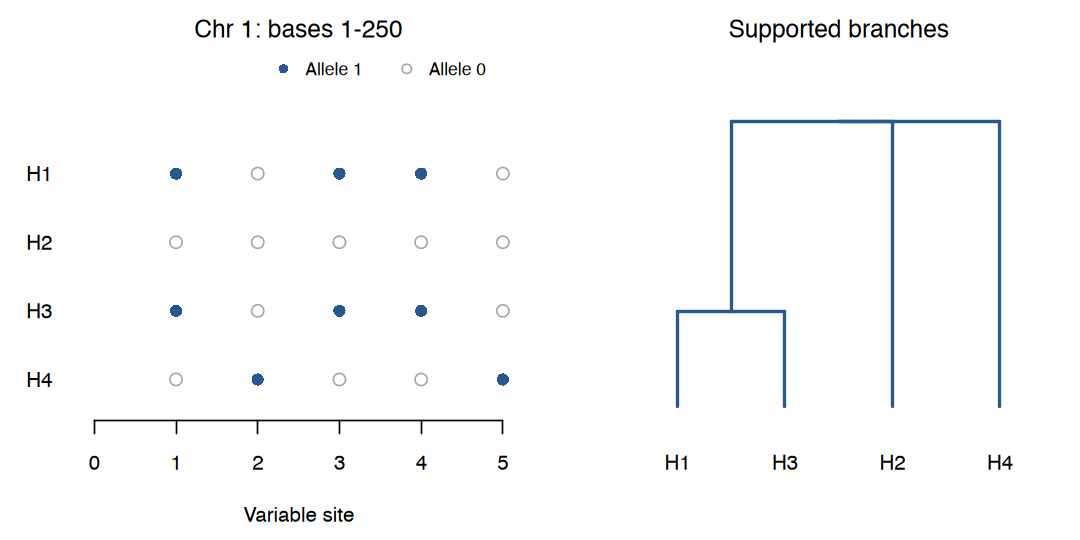

In [5]:
drawFigure("p6_supported_clades", function() {
    par(mfrow = c(1, 2), mar = c(4.6, 3, 2.2, .8), bg = "white")
    drawCarriers(G3, key = TRUE)
    title("Chr 1: bases 1-250")
    drawTree(consensus3$tree, title = "Supported branches")
})


## Mutation counts give uncertain branch times

For a proposed local tree, $M_b\sim\mathrm{Poisson}(\mu L t_b)$ gives
$\log\mathcal L=\sum_b\{M_b\log(\mu L t_b)-\mu L t_b\}+C$.
Fit nonnegative branch durations and leave unsupported splits unresolved.
Here the supported H1–H3 ancestor is fitted at the zero-age boundary;
the root estimate is about 267 generations. A boundary estimate is not a
claim that the sampled copies share a parent in the current generation.

For a fixed pair, use $D_{ij}\sim\mathrm{Poisson}(2\mu LT_{ij})$.
The simultaneous intervals use all six predeclared pairs. Their stated
coverage belongs to the single-tree infinite-sites model; recombination
and recurrent mutation in the actual forward data can violate it.


In [6]:
fit3 <- ptiFitAges(G3, mu, L)
pairs3 <- ptiPairIntervals(G3, mu, L)
intervals3 <- lapply(fit3$node_ages$clade, function(key)
    ptiCladeInterval(pairs3,as.integer(strsplit(key,",",fixed=TRUE)[[1]])))
age_table <- fit3$node_ages
age_table$lower <- vapply(intervals3,`[[`,0,"lower")
age_table$upper <- vapply(intervals3,`[[`,0,"upper")
frozen_inference <- serialize(list(consensus3,fit3,pairs3),NULL)
truth3 <- ancestry_truth$four[["125"]]
age_table$recorded_age <- unname(truth3$ages[age_table$clade])
print(age_table,row.names=FALSE)
stopifnot(identical(frozen_inference,serialize(list(consensus3,fit3,pairs3),NULL)))


   clade estimate_min estimate_max same_height_across_best_fits    lower     upper recorded_age
     1,3       0.0000       0.0000                         TRUE  0.00000  438.4511           44
 1,2,3,4     266.6667     266.6667                         TRUE 82.52364 1153.4474          301


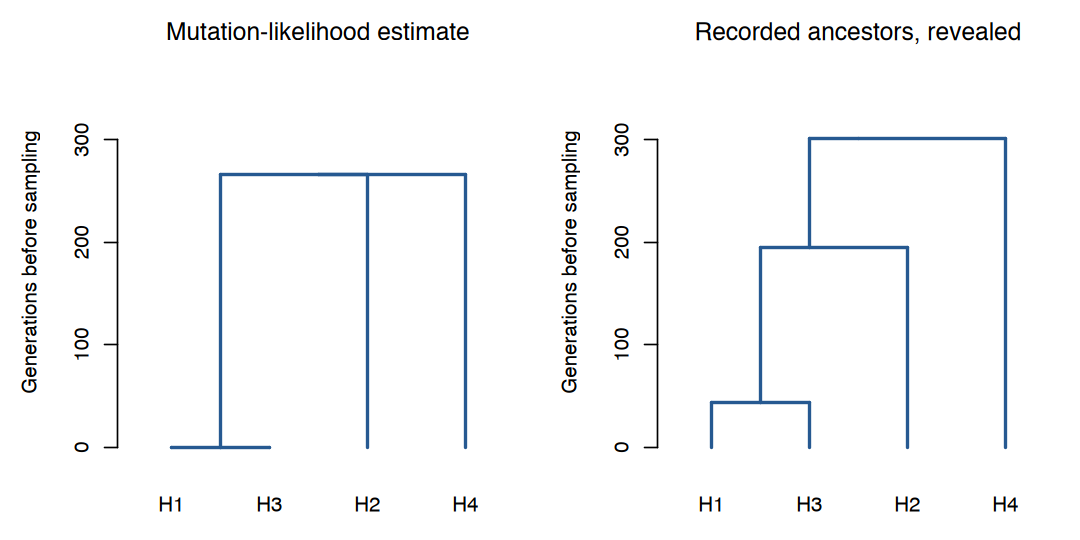

In [7]:
drawFigure("p6_tree_time_inference", function() {
    par(mfrow = c(1, 2), mar = c(3, 4.5, 2.4, .8), bg = "white")
    estimated <- setNames(age_table$estimate_min, age_table$clade)
    maximum <- max(c(estimated, truth3$ages)) * 1.2
    drawTree(consensus3$tree, estimated, maximum, "Mutation-likelihood estimate")
    drawTree(truth3$tree, truth3$ages, maximum, "Recorded ancestors, revealed")
})


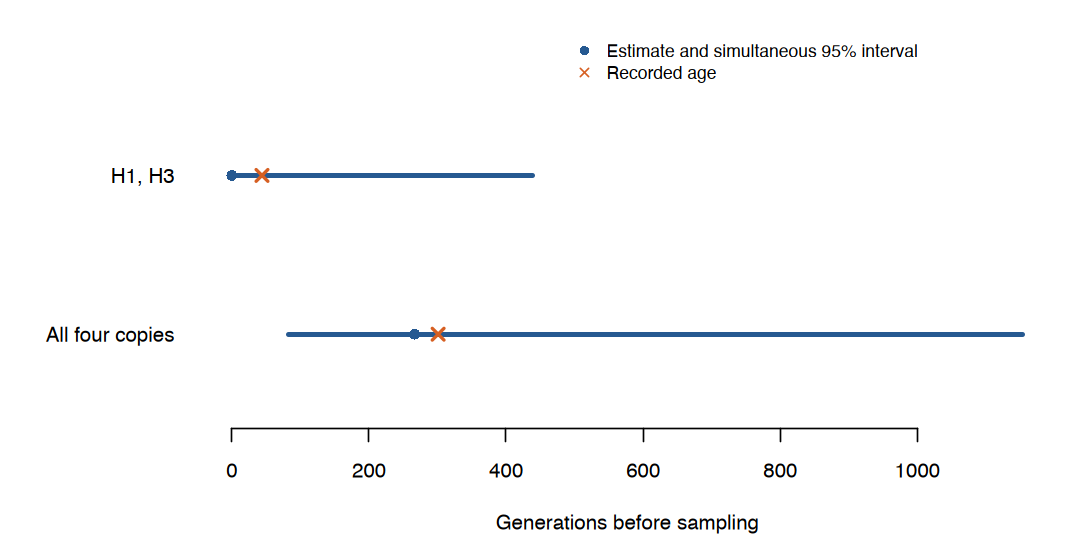

In [8]:
drawFigure("p6_ancestral_time_intervals", function() {
    par(mar = c(4.3, 7.7, 1.3, 1), bg = "white")
    table <- age_table[2:1, ]
    plot(NA, xlim = range(c(0, table$upper)), ylim = c(.5, 2.8), yaxt = "n",
         xlab = "Generations before sampling", ylab = "", bty = "n")
    axis(2, 1:2, c("All four copies", "H1, H3"), las = 1, tick = FALSE)
    segments(table$lower, 1:2, table$upper, 1:2, lwd = 3, col = blue)
    points(table$estimate_min, 1:2, pch = 16, col = blue)
    points(table$recorded_age, 1:2, pch = 4, cex = 1.2, lwd = 2, col = orange)
    legend("topright", c("Estimate and simultaneous 95% interval", "Recorded age"),
           col = c(blue, orange), pch = c(16, 4), bty = "n", y.intersp = 1.8, cex = .85)
}, height = 3.1)


## Linked carrier groups

Keep the same four haplotypes and inspect chromosome 1 bases 1–1,000.
Overlapping nonnested carrier groups cannot be clades of one tree under
infinite sites. Find the fewest compatible blocks, keeping all equally
minimal partitions. These are data constraints under that model;
recurrent mutations can also create conflicts.


In [9]:
positions4 <- 0:999
G4 <- observed$haplotypes[samples,1:1000,drop=FALSE]
constraints4 <- ptiLinkedConstraints(G4,positions4)
quarters <- seq(0,1000,length.out=5)
local_consensus <- lapply(1:4,function(i)ptiConsensus(G4[,positions4>=quarters[i] &
    positions4<quarters[i+1],drop=FALSE]))
print(data.frame(quarter=1:4,compatible_trees=vapply(local_consensus,`[[`,0L,"compatible_count")))
print(list(minimum_blocks=constraints4$minimum_blocks,
    minimal_partitions=length(constraints4$minimal_cut_sets)))


  quarter compatible_trees
1       1                3
2       2                3
3       3                1
4       4                1


$minimum_blocks
[1] 3

$minimal_partitions
[1] 22



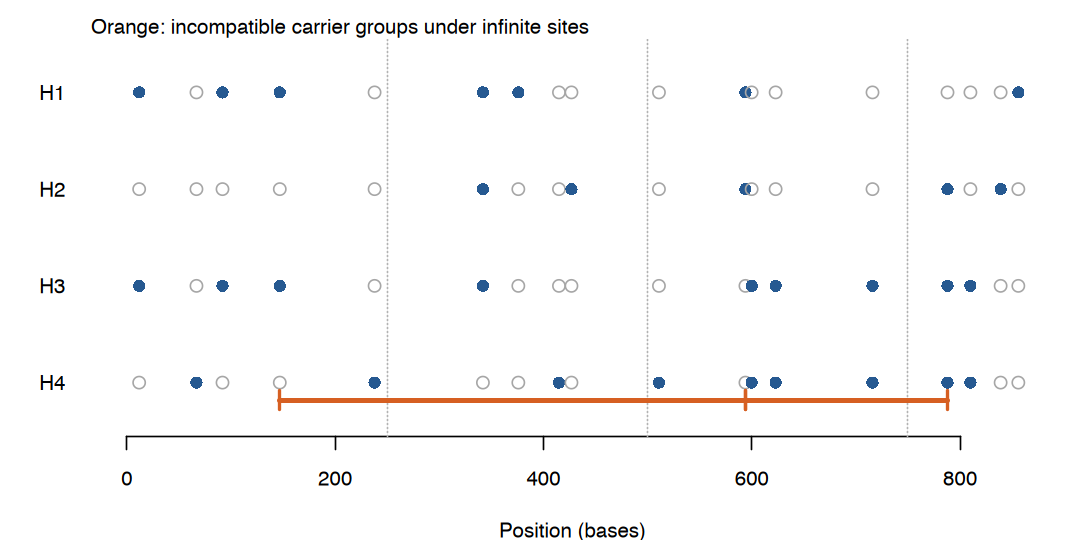

In [10]:
drawFigure("p6_linked_carriers", function() {
    par(mar = c(4, 3.5, 1.5, 1), bg = "white")
    drawCarriers(G4, positions4)
    abline(v = quarters[2:4], lty = 3, col = "gray70")
    w <- constraints4$disjoint_witnesses
    for (i in seq_len(nrow(w))) {
        segments(w$left[i], .82, w$right[i], .82, col = orange, lwd = 3)
        segments(c(w$left[i], w$right[i]), .72, c(w$left[i], w$right[i]), .92,
                 col = orange, lwd = 2)
    }
    mtext("Orange: incompatible carrier groups under infinite sites", 3, line = .1, adj = 0)
})


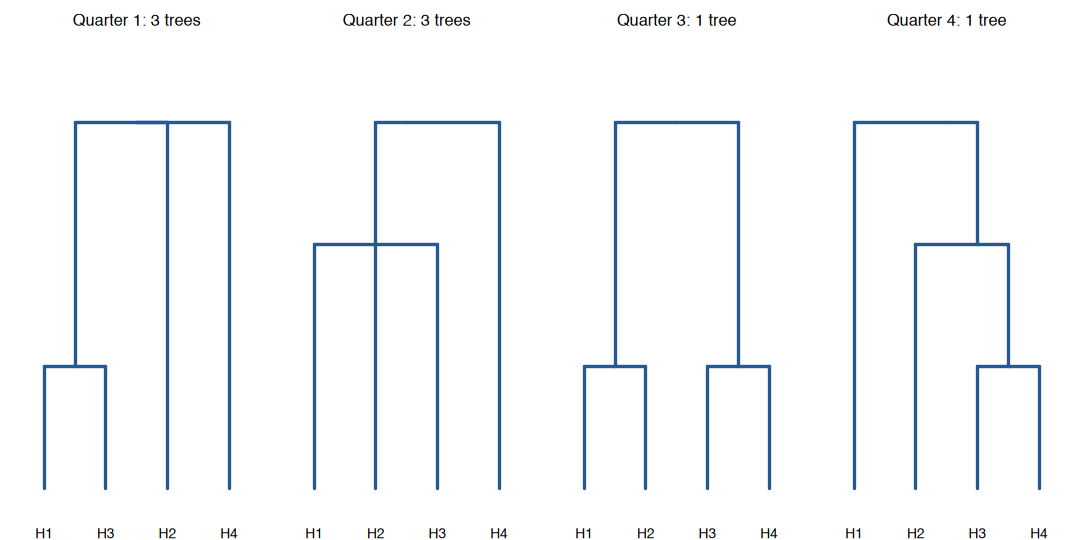

In [11]:
drawFigure("p6_local_constraints", function() {
    par(mfrow = c(1, 4), mar = c(2, .6, 2.3, .4), bg = "white")
    for (i in 1:4) drawTree(local_consensus[[i]]$tree,
        title = paste0("Quarter ", i, ": ", local_consensus[[i]]$compatible_count,
                       if (local_consensus[[i]]$compatible_count == 1) " tree" else " trees"))
}, width = 10, height = 3.1)


## Compare fixed windows of the same chromosome

Fit bases 1–250 and 9,751–10,000 without consulting the ancestry.
The red marks identify the recorded tree at each window midpoint.
They do not imply that its genealogy is constant across all 250 bases.
No breakpoint or root age was prescribed to generate this example.


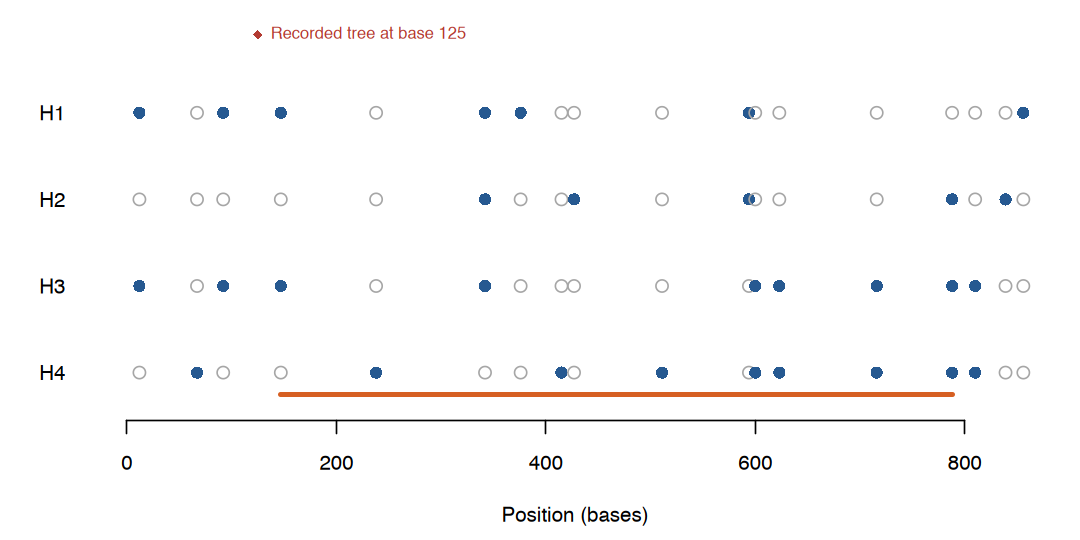

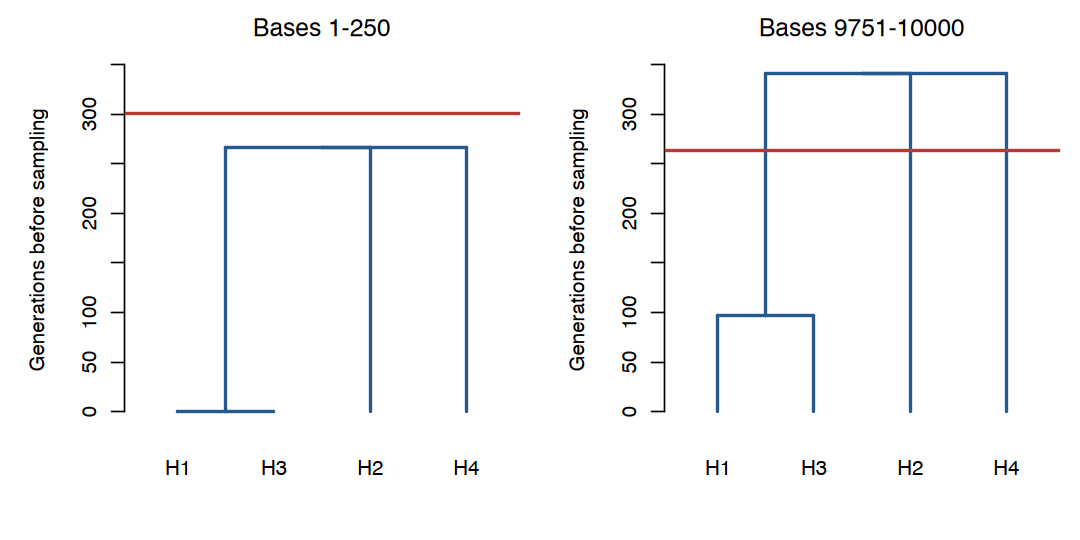

In [12]:
windows <- list(first=c(1L,250L),last=c(9751L,10000L))
local_fits <- lapply(windows,function(w)ptiFitAges(observed$haplotypes[samples,
    seq.int(w[1],w[2]),drop=FALSE],mu,diff(w)+1L))
local_truth <- ancestry_truth$four[c("125","9875")]
drawFigure("local_tree_change",function(){
    par(mar=c(4.6,3.5,2.5,.8))
    drawCarriers(G4,positions4)
    w<-constraints4$disjoint_witnesses
    for(i in seq_len(nrow(w))) segments(w$left[i],.75,w$right[i],.75,col=orange,lwd=3)
    points(125,4.9,pch=18,col="#B33B32",xpd=NA)
    text(125,4.9,"Recorded tree at base 125",pos=4,cex=.8,col="#B33B32",xpd=NA)
},height=4)
drawFigure("inferred_local_tree_times",function(){
    par(mfrow=c(1,2),mar=c(4.4,4.8,2.1,.8))
    ymax<-max(unlist(lapply(local_truth,function(t)t$ages)))*1.15
    for(j in 1:2){
        f<-local_fits[[j]]
        ages<-setNames(f$node_ages$estimate_min,f$node_ages$clade)
        drawTree(f$consensus$tree,ages,ymax,c("Bases 1-250","Bases 9751-10000")[j])
        abline(h=local_truth[[j]]$ages["1,2,3,4"],col="#B33B32",lwd=2)
    }
},width=7.5,height=3.6)


## Check the mutation likelihood conditionally

Hold the recorded midpoint tree fixed and simulate 200 independent
infinite-sites mutation overlays with the same rate and 250-base length.
This isolates the clock model from recombination and recurrent mutation;
it is a conditional check, using ancestry already generated by the main
population. Include uninformative and unresolved draws.


In [13]:
fixed_tree <- pgMakeTree(ancestry_truth$trees[["125"]]$nodes,
    ancestry_truth$trees[["125"]]$edges,
    ancestry_truth$trees[["125"]]$sample_nodes,
    ancestry_truth$trees[["125"]]$sample_ids,"recorded midpoint")
# Restrict the existing tree to the four observed labels.
fixed <- recordedSubset(fixed_tree)
keys <- ptiTreeClades(fixed$tree)
ids <- setNames(seq_along(keys),vapply(keys,ptiKey,""))
ages <- c(setNames(rep(0,4),as.character(1:4)),fixed$ages)
parents <- cladeNodes(fixed$tree)$parent
edges <- data.frame(parent=unname(ids[parents[!is.na(parents)]]),
    child=unname(ids[names(parents)[!is.na(parents)]]))
conditional_tree <- pgMakeTree(data.frame(id=seq_along(ids),time=unname(ages[names(ids)])),
    edges,unname(ids[as.character(1:4)]),paste0("H",1:4),"fixed recorded midpoint tree")
recovery <- do.call(rbind,lapply(1:200,function(i){
    dna<-pgMutateTree(conditional_tree,L,mu,mutation_seed=11814900L+i)
    f<-ptiFitAges(dna$haplotypes,mu,L)
    interval<-ptiCladeInterval(ptiPairIntervals(dna$haplotypes,mu,L),1:4)
    root<-fixed$ages["1,2,3,4"]
    data.frame(compatible=f$consensus$compatible_count,
        estimated_root=f$node_ages$estimate_min[f$node_ages$clade=="1,2,3,4"],
        recorded_root=unname(root),covered=interval$lower<=root & root<=interval$upper)
}))
print(c(replicates=nrow(recovery),simultaneous_root_coverage=mean(recovery$covered)))


                replicates simultaneous_root_coverage 
                       200                          1 


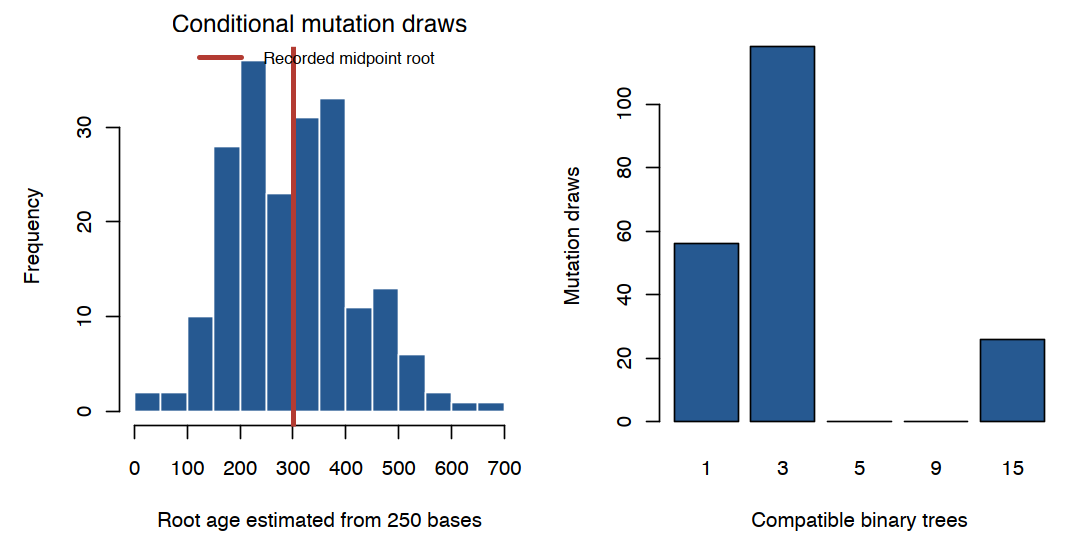

In [14]:
drawFigure("p6_tree_recovery",function(){
    par(mfrow=c(1,2),mar=c(4.4,4.6,1.8,.8))
    hist(recovery$estimated_root,breaks=20,col=blue,border="white",
        xlab="Root age estimated from 250 bases",main="Conditional mutation draws")
    abline(v=recovery$recorded_root[1],col="#B33B32",lwd=3)
    legend("topright","Recorded midpoint root",col="#B33B32",lwd=3,bty="n",cex=.8)
    barplot(table(factor(recovery$compatible,levels=c(1,3,5,9,15))),col=blue,
        xlab="Compatible binary trees",ylab="Mutation draws")
})


## Fit size and growth using the same sample

Use all eight chromosomes of H1–H12. Keep founder size 20, the 20-generation
small-population interval and present size 1,000 specified. Fit ancestral
size and growth duration using the demographic SFS expectation and a
Poisson composite likelihood. Resample chromosomes for uncertainty.

The calculation adapts Daniel Nachun's `.sfs_expected_single_pop` in
demographyTools. It accumulates waiting-time components over the size
epochs and averages over coalescent genealogies.
Its infinite-sites, ancestral-equilibrium approximation differs from the
finite forward burn-in and recurrent mutation, so test predictions on the
observed spectrum instead of treating the fitted parameters as exact truth.

The chromosomes share a pedigree. The bootstrap measures chromosome
variation within this realized sample; population-to-population variation
and model approximation contribute additional uncertainty.


         parameter truth estimate    lower    upper
     ancestralSize   100 102.3788 85.96609 124.8254
 growthGenerations    40  30.0000 25.00000  35.1250


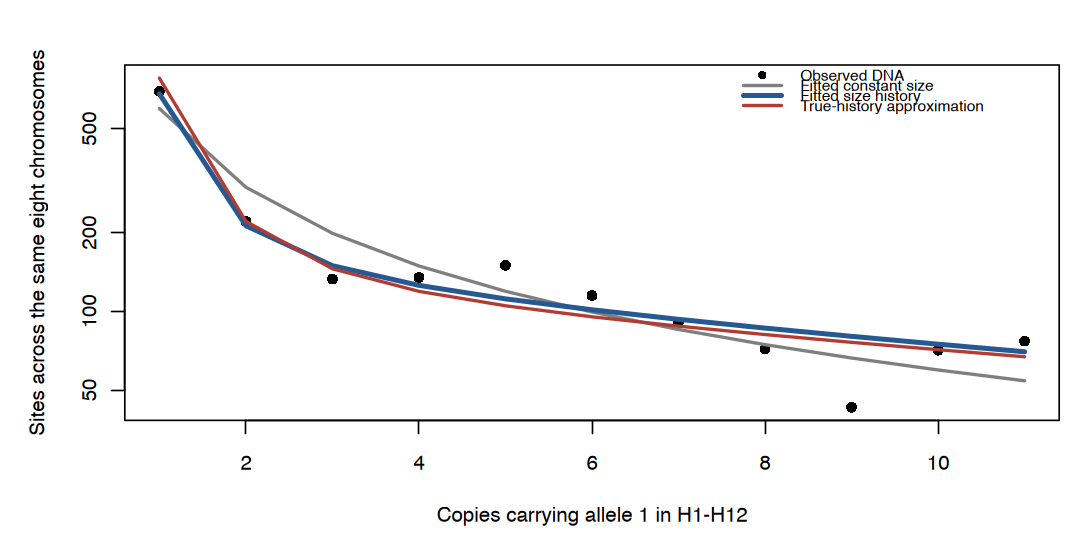

In [15]:
spectra <- t(vapply(1:8,function(j)sfs(observed$haplotypes[1:12,
    ((j-1)*10000+1):(j*10000),drop=FALSE]),integer(11)))
growth <- fitHistorySpectrum(spectra,mu,10000)
set.seed(20261107)
bootstrap <- replicate(40,fitHistorySpectrum(spectra[sample.int(8,8,replace=TRUE),],
    mu,10000)$estimate)
interval <- apply(bootstrap,1,quantile,c(.025,.975))
print(data.frame(parameter=names(growth$estimate),truth=c(100,40),
    estimate=unname(growth$estimate),lower=interval[1,],upper=interval[2,]),row.names=FALSE)
drawFigure("sfs_history_fit",function(){
    par(mar=c(4.6,4.8,2.5,.8))
    truth_expected<-expectedHistorySFS(12,c(100,head(c(20,
        populationSizeSchedule(populationHistoryDesign()$candidates$recent_founding,
            populationHistoryDesign()$design)[-1]),-1)),mu,80000)
    plot(1:11,growth$observed,pch=16,log="y",xlab="Copies carrying allele 1 in H1-H12",
        ylab="Sites across the same eight chromosomes",ylim=range(growth$observed,
            growth$expected,growth$constantExpected,truth_expected))
    lines(1:11,growth$constantExpected,col="gray50",lwd=2)
    lines(1:11,growth$expected,col=blue,lwd=3)
    lines(1:11,truth_expected,col="#B33B32",lwd=2)
    legend("topright",c("Observed DNA","Fitted constant size","Fitted size history",
        "True-history approximation"),col=c("black","gray50",blue,"#B33B32"),
        pch=c(16,NA,NA,NA),lty=c(NA,1,1,1),lwd=c(NA,2,3,2),bty="n",cex=.75)
},width=7,height=4.5)


## A specified-tree calculation

Suppose copies 1 and 2 share an internal branch. Put one mutation on that branch
and one on each terminal branch. This gives five segregating sites, four singletons
and one doubleton. These constructed sites are a schematic for reading SFS bins, not another population simulation.


In [16]:
carriers <- list(c(1, 2), 1, 2, 3, 4)
G <- matrix(0L, nrow = 4, ncol = length(carriers))
for (site in seq_along(carriers)) G[carriers[[site]], site] <- 1L
rownames(G) <- paste0('copy ', 1:4)
colnames(G) <- paste0('site ', 1:5)
G
stopifnot(identical(as.integer(colSums(G)), c(2L, 1L, 1L, 1L, 1L)))


,site 1,site 2,site 3,site 4,site 5
copy 1,1,1,0,0,0
copy 2,1,0,1,0,0
copy 3,0,0,0,1,0
copy 4,0,0,0,0,1


Let $\xi_i$ count sites with $i$ derived copies. The same matrix gives $S$ and
$\pi_{\rm region}$, the average pairwise difference. Averaged over neutral constant-size
genealogies, $E(\xi_i)=\theta/i$; a single small tree can differ from that expectation.


S pi_region   theta_W 
 5.000000  2.666667  2.727273

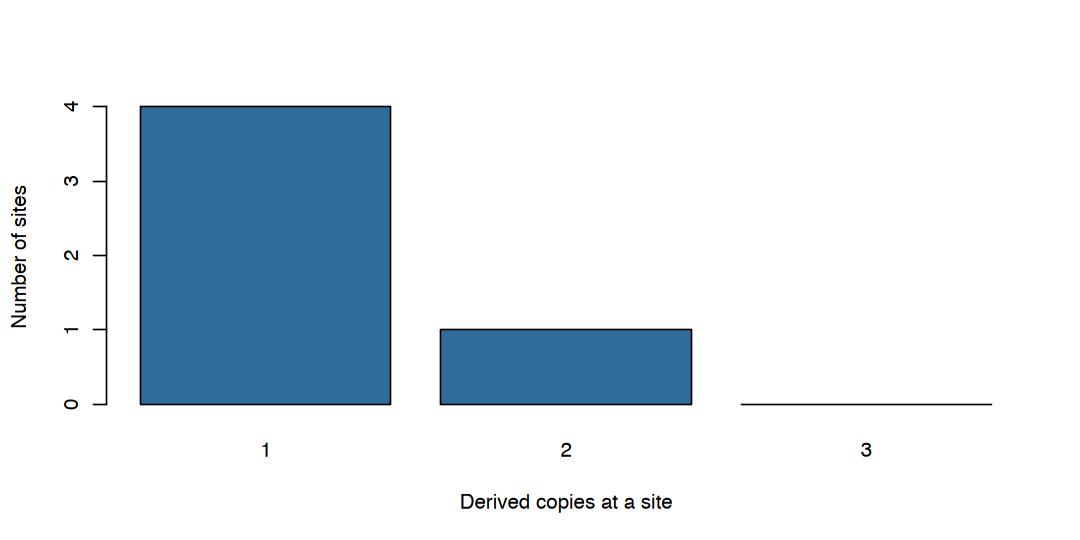

In [17]:
derived_count <- colSums(G)
S <- sum(derived_count > 0 & derived_count < nrow(G))
pi_region <- mean(as.vector(dist(G, method = 'manhattan')))
xi <- tabulate(derived_count, nbins = nrow(G) - 1)
theta_W <- S / sum(1 / seq_len(nrow(G) - 1))
stopifnot(S == 5, abs(pi_region - 8 / 3) < 1e-12)
barplot(xi, names.arg = seq_along(xi), col = '#306C9A',
        xlab = 'Derived copies at a site', ylab = 'Number of sites')
c(S = S, pi_region = pi_region, theta_W = theta_W)


The shared-branch mutation contributes more to pairwise diversity than a singleton;
both count once toward $S$. To check why an SFS alone cannot identify a labeled tree,
change only which samples carry the first site's derived allele.


In [18]:
G_control <- G
G_control[, 1] <- c(1, 0, 1, 0)
stopifnot(identical(colSums(G_control), colSums(G)),
          ptiKey(ptiConsensus(G)$supported_clades[[1]]) == "1,2",
          ptiKey(ptiConsensus(G_control)$supported_clades[[1]]) == "1,3")
cat("Same SFS; supported clade changes from {H1,H2} to {H1,H3}.\n")


Same SFS; supported clade changes from {H1,H2} to {H1,H3}.


Sources: Pritchard, Sections 2.2–2.3 and 3.3; Gorroochurn Notes,
Sections 8.11–8.13; Daniel Nachun's demographyTools and tskitR.
The four-copy enumeration is a small constrained likelihood calculation.
The larger linked-sample notebook uses the source-derived haplotype-matching
and inside–outside methods.
